In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(r"Admission_Predict_Ver1.1.csv")

In [3]:
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [4]:
df.shape

(500, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         500 non-null    int64  
 1   GRE Score          500 non-null    int64  
 2   TOEFL Score        500 non-null    int64  
 3   University Rating  500 non-null    int64  
 4   SOP                500 non-null    float64
 5   LOR                500 non-null    float64
 6   CGPA               500 non-null    float64
 7   Research           500 non-null    int64  
 8   Chance of Admit    500 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 35.3 KB


In [6]:
df.duplicated().sum()

0

In [7]:
df.drop(columns =["Serial No."], inplace = True)

In [8]:
df.columns.tolist()

['GRE Score',
 'TOEFL Score',
 'University Rating',
 'SOP',
 'LOR ',
 'CGPA',
 'Research',
 'Chance of Admit ']

In [9]:
x = df.drop(columns = ['Chance of Admit '], axis = 1)

In [10]:
y = df.drop(x, axis = 'columns')

In [11]:
x.shape

(500, 7)

In [12]:
y.shape

(500, 1)

In [13]:
x.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
0,337,118,4,4.5,4.5,9.65,1
1,324,107,4,4.0,4.5,8.87,1
2,316,104,3,3.0,3.5,8.00,1
3,322,110,3,3.5,2.5,8.67,1
4,314,103,2,2.0,3.0,8.21,0


In [14]:
y.head()

,Chance of Admit
0,0.92
1,0.76
2,0.72
3,0.80
4,0.65


In [15]:
from sklearn.preprocessing import MinMaxScaler

In [16]:
mms = MinMaxScaler()

In [17]:
x = mms.fit_transform(x)

In [18]:
type(x)

numpy.ndarray

In [19]:
# Splitting the data into training and testing
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2)

In [20]:
x_train.shape

(400, 7)

In [21]:
y_train.shape

(400, 1)

In [22]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Flatten

In [23]:
model = Sequential()

In [24]:
model.add(Dense(128, activation = 'relu', input_dim = (7)))
model.add(Dense(64, activation = 'relu'))
model.add(Dense(32, activation = 'relu'))
model.add(Dense(1, activation = "linear"))
# In regression model, activation function for output node will always be "linear"

In [25]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               1024      
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 dense_2 (Dense)             (None, 32)                2080      
                                                                 
 dense_3 (Dense)             (None, 1)                 33        
                                                                 
Total params: 11393 (44.50 KB)
Trainable params: 11393 (44.50 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [26]:
model.compile(loss = "mean_squared_error", optimizer = 'adam', )

In [27]:
history = model.fit(x_train, y_train, epochs = 100, validation_split = 0.2)

Epoch 1/100
10/10 [==============================] - 1s 20ms/step - loss: 0.2285 - val_loss: 0.0210
Epoch 2/100
10/10 [==============================] - 0s 5ms/step - loss: 0.0338 - val_loss: 0.0252
Epoch 3/100
10/10 [==============================] - 0s 5ms/step - loss: 0.0119 - val_loss: 0.0140
Epoch 4/100
10/10 [==============================] - 0s 5ms/step - loss: 0.0089 - val_loss: 0.0089
Epoch 5/100
10/10 [==============================] - 0s 5ms/step - loss: 0.0063 - val_loss: 0.0076
Epoch 6/100
10/10 [==============================] - 0s 5ms/step - loss: 0.0055 - val_loss: 0.0068
Epoch 7/100
10/10 [==============================] - 0s 5ms/step - loss: 0.0049 - val_loss: 0.0062
Epoch 8/100
10/10 [==============================] - 0s 5ms/step - loss: 0.0046 - val_loss: 0.0057
Epoch 9/100
10/10 [==============================] - 0s 4ms/step - loss: 0.0043 - val_loss: 0.0054
Epoch 10/100
10/10 [==============================] - 0s 5ms/step - loss: 0.0040 - val_loss: 0.0052
Epoch 11

In [28]:
y_pred = model.predict(x_test)

4/4 [==============================] - 0s 2ms/step


In [29]:
y_pred[0:5]

array([[0.6573274 ],
       [0.6009444 ],
       [0.8059531 ],
       [0.63867015],
       [0.79816085]], dtype=float32)

In [30]:
from sklearn.metrics import r2_score

In [31]:
r2_score(y_pred, y_test)

0.7908558175000985

# Let's plot training and validation loss

In [32]:
import matplotlib.pyplot as plt

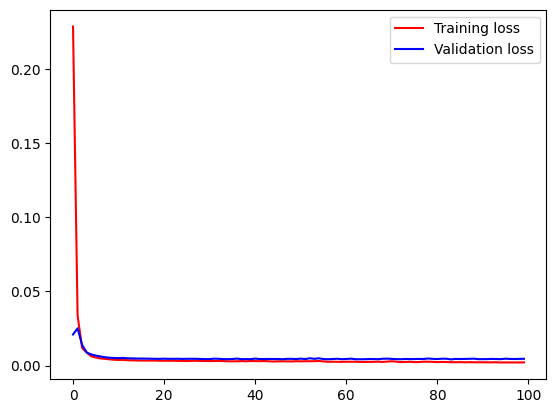

In [34]:
plt.plot(history.history["loss"], color = "red", label = "Training loss")
plt.plot(history.history["val_loss"], color = "blue" , label = "Validation loss")
plt.legend()

In [35]:
history.history['loss'][1:6]

[0.03383764252066612,
 0.01190938986837864,
 0.008904201909899712,
 0.006296374835073948,
 0.00550480093806982]

In [36]:
history.history["val_loss"][1:6]

[0.02518484927713871,
 0.01398123987019062,
 0.008852836675941944,
 0.007586860563606024,
 0.006809926591813564]